In [1]:
import pandas as pd
import statsmodels.formula.api as smf
import scipy.stats as st
import matplotlib.pyplot as plt
from statsmodels.iolib.summary2 import summary_col
import numpy as np
from statsmodels.stats.diagnostic import het_breuschpagan

url = 'https://raw.githubusercontent.com/git-iush/large_family/refs/heads/main/data2.parquet'

In [2]:
df = pd.read_parquet(url)
df.head()

,SERIAL,HHWT,CLUSTER,STRATA,PERNUM,PERWT,NCHILD,SEX,AGE,MARST,...,BLACK,AIAN,API,OTHER,MULTR,HISP,EXPANSION,WELFARE,PRSNINC,YRSEDUC
0,4,4.0,2024000000041,280201,1,4.0,0,2,22,6,...,0,0,1,0,0,0,0,0.0,1000.0,13
1,9,74.0,2024000000091,280301,1,74.0,0,2,18,6,...,1,0,0,0,0,0,0,0.0,5100.0,12
2,12,55.0,2024000000121,160001,1,55.0,0,2,19,6,...,0,0,0,0,0,0,0,0.0,0.0,12
3,15,17.0,2024000000151,120201,1,17.0,0,2,19,6,...,0,0,0,0,0,0,0,0.0,6000.0,12
4,19,71.0,2024000000191,10001,1,71.0,0,2,23,6,...,0,0,0,0,0,0,0,0.0,0.0,13


In [13]:
medicaid_mapping = {1:0, 2:1}
df['MEDICAID'] = df['HINSCAID'].map(medicaid_mapping)
df['MEDFARE'] = df['MEDICAID'] * df['WELFARE']

df['FAMINC'] = df['FTOTINC'] - df['INCTOT']
df['PRSNINC'] = df['PRSNINC'] / 10000
df['FAMINC'] = df['FAMINC'] / 10000
df['PRSNINC2'] = df['PRSNINC'] ** 2
df['FAMINC2'] = df['FAMINC'] ** 2

df['AGE2'] = df['AGE'] ** 2

df['HIGHSCHOOL'] = [1 if i == 63 or i==64 else 0 for i in df['EDUCD']]
df['BACHELORS'] = [1 if i == 101 else 0 for i in df['EDUCD']]
df['ADVANCED'] = [1 if i>=114 else 0 for i in df['EDUCD']]

df['MARD'] = [1 if i==1 or i==2 or i==3 else 0 for i in df['MARST']]

df['LARGEFAM'] = [1 if i >= 3 else 0 for i in df['NCHILD']]

In [14]:
df['MARD'] = [1 if i <= 3 else 0 for i in df['MARST']]

In [15]:
model_df = df[['NCHILD', 'MEDICAID', 'WELFARE', 'MEDFARE', 'AGE', 'AGE2', 'PRSNINC', 'PRSNINC2', 'FAMINC', 'FAMINC2', 'MARD']]
model_df.dropna(inplace=True)
model_df.shape

(678476, 11)

In [16]:
pred = smf.ols('NCHILD ~ MEDICAID + WELFARE + MEDFARE + AGE + AGE2 + PRSNINC + PRSNINC2 + FAMINC + FAMINC2 + MARD', data=model_df).fit()
print(pred.summary())

                            OLS Regression Results                            
Dep. Variable:                 NCHILD   R-squared:                       0.308
Model:                            OLS   Adj. R-squared:                  0.307
Method:                 Least Squares   F-statistic:                 3.013e+04
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        21:27:08   Log-Likelihood:            -9.7079e+05
No. Observations:              678476   AIC:                         1.942e+06
Df Residuals:                  678465   BIC:                         1.942e+06
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -2.5659      0.014   -180.062      0.0

In [17]:
#Counting women ages 15-50
ages = [i for i in range(15, 50)]

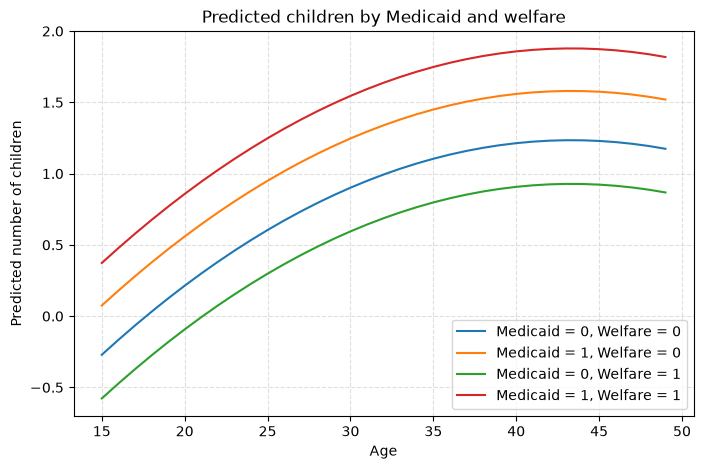

In [18]:
plt.figure(figsize=(8, 5))
#running a loop for the pooled
for m, w in zip([0, 1, 0, 1], [0, 0, 1, 1]):
    new = pd.DataFrame({'AGE': ages,
                        'MEDICAID': [m for i in ages],
                        'WELFARE': [w for i in ages],
                        'PRSNINC': [model_df['PRSNINC'].mean() for i in ages],
                        'FAMINC': [model_df['FAMINC'].mean() for i in ages],
                        'MARD': [model_df['MARD'].mean() for i in ages]})
 #same interaction terms for the model
    new['AGE2'] = new['AGE']**2
    new['PRSNINC2'] = new['PRSNINC']**2
    new['FAMINC2'] = new['FAMINC']**2
    new['MEDFARE'] = new['MEDICAID'] * new['WELFARE']

    plt.plot(ages, pred.predict(new), label=f'Medicaid = {m}, Welfare = {w}')

plt.xlabel('Age')
plt.ylabel('Predicted number of children')
plt.title('Predicted children by Medicaid and welfare')
plt.legend()
plt.grid(alpha=0.4, ls='--')
plt.show()